# 💳 Digital Lending & Credit Risk Analysis

### Exploratory Data Analysis (EDA) Project

**Project Type:** FinTech / Credit Risk / Exploratory Data Analysis  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Dataset:** Credit Risk / Loan Default Dataset  
**Objective:** Understand borrower characteristics, loan behaviour and factors associated with loan default.

---

## Project Overview

Digital lending platforms process large volumes of loan applications and need to understand borrower profiles, loan characteristics and repayment risk.

This project performs a complete exploratory analysis of a credit-risk dataset to answer business questions such as:

- Which borrower characteristics are associated with loan default?
- How do income and loan size relate to repayment risk?
- Which loan purposes have relatively higher default rates?
- How does loan grade relate to interest rate and default?
- Does a higher loan burden correspond to higher default rates?
- How do previous credit defaults relate to current loan status?

> **Important:** This is an EDA project. The analysis identifies patterns and associations in the observed data; it does not establish causal relationships or constitute a production credit-scoring model.


## Table of Contents

1. Business Problem & Objectives  
2. Import Libraries  
3. Load Dataset  
4. Dataset Overview  
5. Understanding the Variables  
6. Data Quality Assessment  
7. Data Cleaning  
8. Feature Engineering  
9. Exploratory Data Analysis  
10. Borrower Profile Analysis  
11. Loan Characteristics Analysis  
12. Credit Risk & Default Analysis  
13. Relationship & Correlation Analysis  
14. Business Insights  
15. Recommendations  
16. Conclusion & Limitations


## 1. Business Problem

A digital lender needs to understand the characteristics of borrowers and loans associated with repayment risk.

### Key business questions

**Q1.** What is the overall distribution of loan defaults?

**Q2.** How do borrower income and age vary across default and non-default groups?

**Q3.** Which loan purposes have the highest default rates?

**Q4.** How does loan grade relate to default rate and interest rate?

**Q5.** Does loan amount relative to borrower income differ between default and non-default borrowers?

**Q6.** Does previous credit default history show an association with current loan default?

**Q7.** Which borrower segments show comparatively higher observed default rates?

**Q8.** What actionable observations can a digital lender derive from the EDA?


## 2. Importing Required Libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

%matplotlib inline

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")


Libraries imported successfully.


## 3. Loading the Dataset

The original Windows path supplied for this project is used below.

If the CSV is in the same folder as the notebook, the fallback path can be used instead.


In [2]:
# Primary path supplied for the project
file_path = "credit_risk_dataset.csv"

# Keep the dataset in the same folder as this notebook for reproducible execution.
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")


Dataset loaded successfully.


# 4. Dataset Overview


In [3]:
print("Number of rows and columns:", df.shape)


Number of rows and columns: (32581, 12)


In [4]:
print("First 5 records:")
display(df.head())


First 5 records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.00,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.00,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.00,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.00,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.00,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [5]:
print("Last 5 records:")
display(df.tail())


Last 5 records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32576,57,53000,MORTGAGE,1.00,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.00,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.00,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.00,PERSONAL,B,15000,11.48,0,0.10,N,26
32580,66,42000,RENT,2.00,MEDICAL,B,6475,9.99,0,0.15,N,30


In [6]:
print("Column names:")
print(df.columns.tolist())


Column names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [7]:
print("Dataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [8]:
print("Data types:")
display(df.dtypes)


Data types:


person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [9]:
print("Numerical summary:")
display(df.describe())


Numerical summary:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,"32,581.00","32,581.00","31,686.00","32,581.00","29,465.00","32,581.00","32,581.00","32,581.00"
mean,27.73,"66,074.85",4.79,"9,589.37",11.01,0.22,0.17,5.80
std,6.35,"61,983.12",4.14,"6,322.09",3.24,0.41,0.11,4.06
min,20.00,"4,000.00",0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,"38,500.00",2.00,"5,000.00",7.90,0.00,0.09,3.00
50%,26.00,"55,000.00",4.00,"8,000.00",10.99,0.00,0.15,4.00
75%,30.00,"79,200.00",7.00,"12,200.00",13.47,0.00,0.23,8.00
max,144.00,"6,000,000.00",123.00,"35,000.00",23.22,1.00,0.83,30.00


In [10]:
print("Categorical summary:")
display(df.describe(include="object"))


Categorical summary:


C:\Users\ranja\AppData\Local\Temp\ipykernel_17780\2160052553.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


## 5. Understanding the Variables

| Variable | Business Meaning | Type |
|---|---|---|
| `person_age` | Borrower's age | Numerical |
| `person_income` | Annual borrower income | Numerical |
| `person_home_ownership` | Home ownership category | Categorical |
| `person_emp_length` | Employment length in years | Numerical |
| `loan_intent` | Purpose of the loan | Categorical |
| `loan_grade` | Loan risk grade | Categorical |
| `loan_amnt` | Requested loan amount | Numerical |
| `loan_int_rate` | Loan interest rate | Numerical |
| `loan_status` | Current loan default indicator | Binary |
| `loan_percent_income` | Loan amount as a proportion of income | Numerical |
| `cb_person_default_on_file` | Previous credit default recorded | Categorical |
| `cb_person_cred_hist_length` | Length of credit history | Numerical |

### Target variable

`loan_status`

- **0 = Non-default**
- **1 = Default**


# 6. Data Quality Assessment

Before making business conclusions, we need to identify missing values, duplicate records, unusual values and inconsistent observations.


In [11]:
print("Missing values by column:")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing.to_frame("missing_count"))


Missing values by column:


,missing_count
loan_int_rate,3116
person_emp_length,895
person_income,0
person_age,0
person_home_ownership,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0


In [12]:
print("Missing-value percentage:")
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
display(missing_pct.to_frame("missing_percentage"))


Missing-value percentage:


,missing_percentage
loan_int_rate,9.56
person_emp_length,2.75
person_income,0.00
person_age,0.00
person_home_ownership,0.00
loan_intent,0.00
loan_grade,0.00
loan_amnt,0.00
loan_status,0.00
loan_percent_income,0.00


In [13]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 165


In [14]:
print("Unique values per column:")
display(df.nunique().sort_values(ascending=False).to_frame("unique_values"))


Unique values per column:


,unique_values
person_income,4295
loan_amnt,753
loan_int_rate,348
loan_percent_income,77
person_age,58
person_emp_length,36
cb_person_cred_hist_length,29
loan_grade,7
loan_intent,6
person_home_ownership,4


## Initial Data Quality Findings

The dataset contains missing values in `person_emp_length` and `loan_int_rate`.

The raw data also contains extreme values such as very high ages and an employment length of 123 years. These values should be investigated before analysis rather than blindly accepted as valid observations.


In [16]:
print("Potentially unusual age records:")
display(df.loc[df["person_age"] > 100, ["person_age", "person_income", "loan_amnt", "loan_status"]])

print("\nPotentially unusual employment-length records:")
display(df.loc[df["person_emp_length"] > 50, ["person_age", "person_emp_length", "loan_status"]])


Potentially unusual age records:


,person_age,person_income,loan_amnt,loan_status
81,144,250000,4800,0
183,144,200000,6000,0
575,123,80004,20400,0
747,123,78000,20000,0
32297,144,6000000,5000,0



Potentially unusual employment-length records:


,person_age,person_emp_length,loan_status
0,22,123.00,1
210,21,123.00,0


# 7. Data Cleaning

### Cleaning principles

1. Preserve the raw dataset in `df_raw`.
2. Remove exact duplicate rows if any.
3. Treat clearly implausible ages as invalid observations.
4. Treat clearly implausible employment length values as missing.
5. Impute missing numerical values using the median where appropriate.
6. Keep the target variable intact.


In [17]:
# Keep a raw copy
df_raw = df.copy()

# Remove exact duplicates
df = df.drop_duplicates().copy()

print("Rows after removing exact duplicates:", len(df))


Rows after removing exact duplicates: 32416


In [18]:
# Treat clearly implausible ages as missing
df.loc[df["person_age"] > 100, "person_age"] = np.nan

# Treat clearly implausible employment lengths as missing
df.loc[df["person_emp_length"] > 50, "person_emp_length"] = np.nan

print("Invalid age/employment observations converted to NaN.")


Invalid age/employment observations converted to NaN.


In [19]:
# Median imputation for numerical missing values
df["person_age"] = df["person_age"].fillna(df["person_age"].median())
df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())

print("Missing numerical values handled.")


Missing numerical values handled.


In [20]:
print("Missing values after cleaning:")
display(df.isnull().sum())


Missing values after cleaning:


person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

# 8. Feature Engineering

To make the EDA more business-oriented, we create derived variables that represent borrower and loan burden more clearly.


In [21]:
# Loan burden relative to annual income
df["loan_to_income"] = df["loan_amnt"] / df["person_income"]

# Total annual income in a convenient lakh-based representation
df["income_lakh"] = df["person_income"] / 100000

# Loan amount in thousands
df["loan_amount_k"] = df["loan_amnt"] / 1000

# Human-readable default label
df["loan_status_label"] = df["loan_status"].map({
    0: "Non-Default",
    1: "Default"
})

# Previous default label
df["previous_default_label"] = df["cb_person_default_on_file"].map({
    "N": "No Previous Default",
    "Y": "Previous Default"
})

print("Feature engineering completed.")


Feature engineering completed.


In [22]:
# Age groups
df["age_group"] = pd.cut(
    df["person_age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# Income groups based on quartiles
df["income_group"] = pd.qcut(
    df["person_income"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

# Loan amount groups
df["loan_amount_group"] = pd.qcut(
    df["loan_amnt"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

# Interest-rate groups
df["interest_rate_group"] = pd.cut(
    df["loan_int_rate"],
    bins=[0, 8, 12, 16, 25],
    labels=["Low", "Moderate", "High", "Very High"]
)

print("Business-friendly segments created.")


Business-friendly segments created.


# 9. Exploratory Data Analysis

We now move from data preparation to business-focused analysis.

Each section follows:

**Question → Visualization → Observation → Business Interpretation**


# 9.1 Target Variable: Default Distribution

### Question
What proportion of observed loans are in the default category?


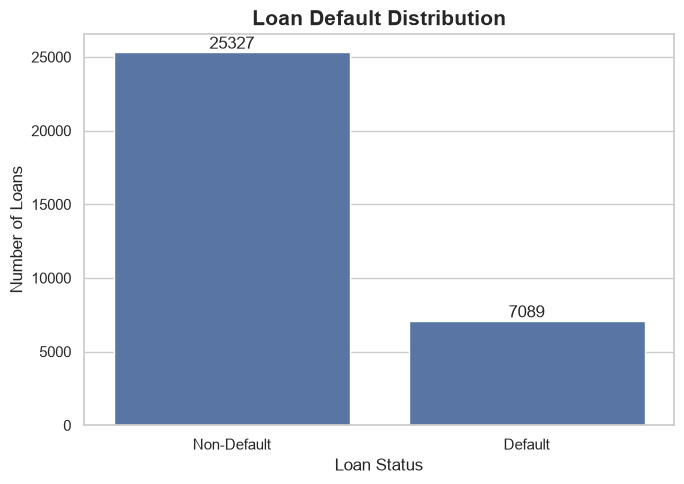

Default rate: 21.87%


In [24]:
status_counts = df["loan_status_label"].value_counts()

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title("Loan Default Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

print("Default rate:", f"{df['loan_status'].mean() * 100:.2f}%")


### Interpretation

The target distribution gives the baseline level of observed defaults in the dataset. This baseline is important because all later segment-level default rates should be compared with the overall default rate.


# 9.2 Borrower Age Distribution


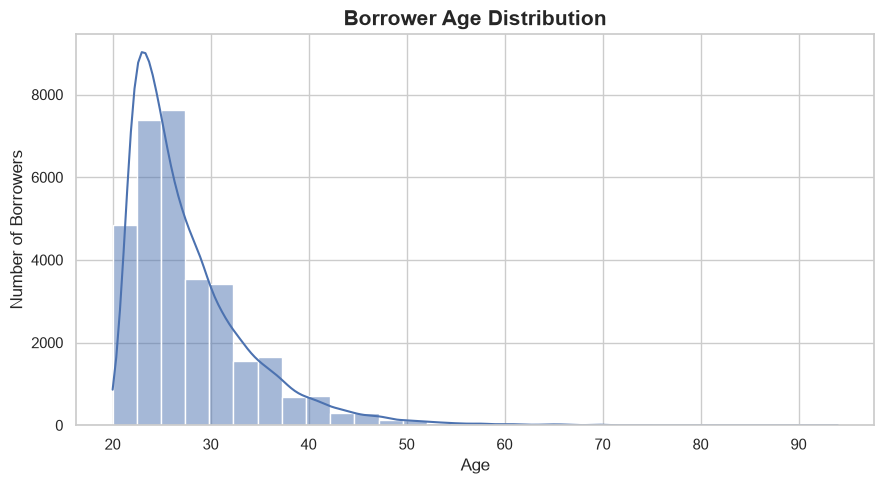

In [25]:
plt.figure(figsize=(9, 5))
sns.histplot(df["person_age"], bins=30, kde=True)
plt.title("Borrower Age Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("Number of Borrowers")
plt.tight_layout()
plt.show()


### Question
Which age groups are most represented among borrowers?


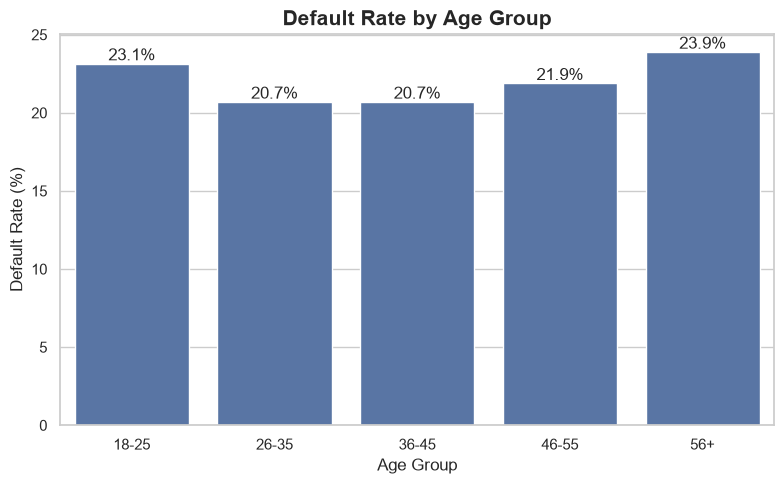

In [26]:
age_default = (
    df.groupby("age_group", observed=False)["loan_status"]
      .mean()
      .mul(100)
      .reset_index(name="default_rate")
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=age_default, x="age_group", y="default_rate")
plt.title("Default Rate by Age Group", fontsize=15, fontweight="bold")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


# 9.3 Income Analysis

### Question
How does borrower income vary across the dataset, and how is default distributed across income groups?


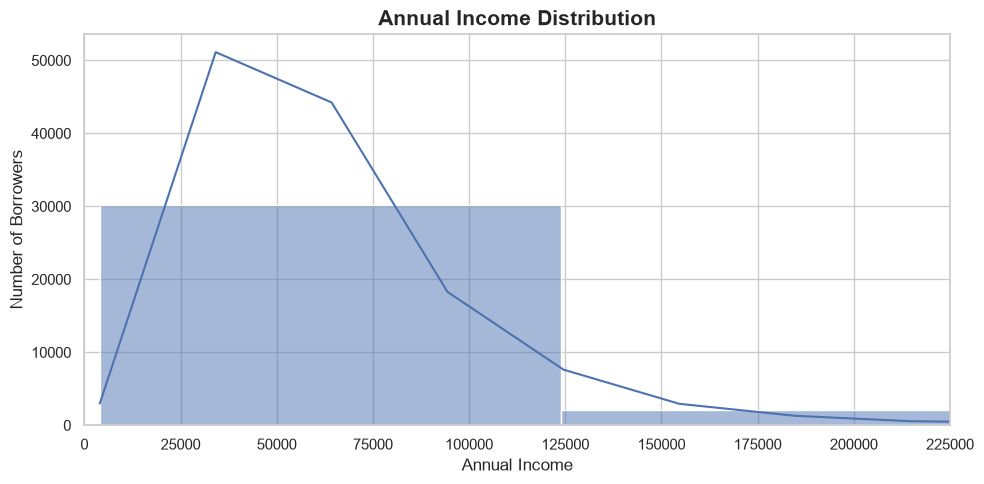

In [27]:
plt.figure(figsize=(10, 5))
sns.histplot(df["person_income"], bins=50, kde=True)
plt.title("Annual Income Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Annual Income")
plt.ylabel("Number of Borrowers")
plt.xlim(0, df["person_income"].quantile(0.99))
plt.tight_layout()
plt.show()


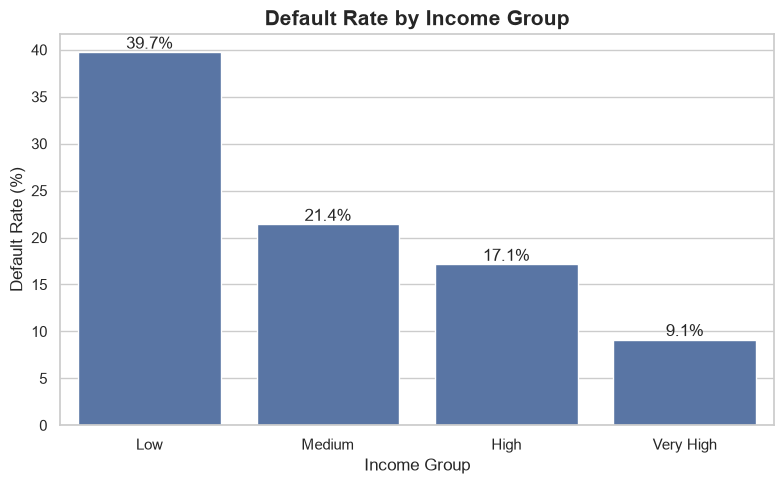

In [28]:
income_default = (
    df.groupby("income_group", observed=False)["loan_status"]
      .mean()
      .mul(100)
      .reset_index(name="default_rate")
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=income_default, x="income_group", y="default_rate")
plt.title("Default Rate by Income Group", fontsize=15, fontweight="bold")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


# 9.4 Home Ownership

### Question
How does observed default rate vary by home ownership?


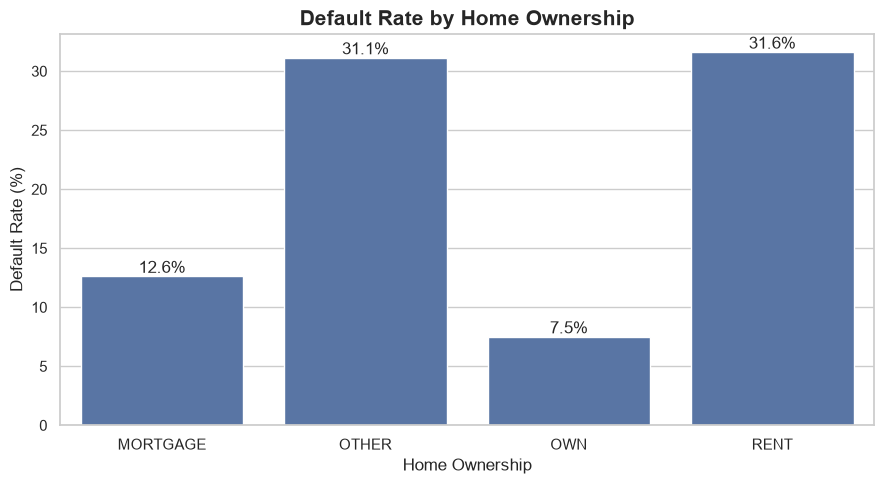

,person_home_ownership,default_rate,count
3,RENT,31.61,16378
1,OTHER,31.13,106
0,MORTGAGE,12.62,13369
2,OWN,7.49,2563


In [29]:
home_default = (
    df.groupby("person_home_ownership")["loan_status"]
      .agg(["mean", "count"])
      .reset_index()
      .rename(columns={"mean": "default_rate"})
)

home_default["default_rate"] *= 100

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=home_default, x="person_home_ownership", y="default_rate")
plt.title("Default Rate by Home Ownership", fontsize=15, fontweight="bold")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

display(home_default.sort_values("default_rate", ascending=False))


# 9.5 Loan Purpose Analysis

### Question
Which loan purposes have relatively higher observed default rates?


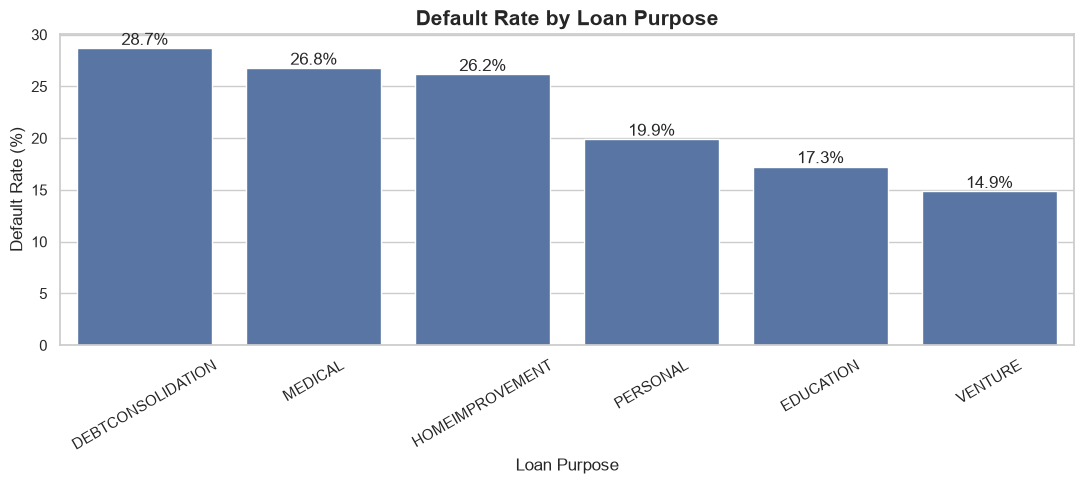

In [30]:
purpose_default = (
    df.groupby("loan_intent")["loan_status"]
      .agg(["mean", "count"])
      .reset_index()
      .rename(columns={"mean": "default_rate"})
)

purpose_default["default_rate"] *= 100

plt.figure(figsize=(11, 5))
ax = sns.barplot(
    data=purpose_default.sort_values("default_rate", ascending=False),
    x="loan_intent",
    y="default_rate"
)
plt.title("Default Rate by Loan Purpose", fontsize=15, fontweight="bold")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


### Business Question

Loan purpose can provide context about how borrowers intend to use borrowed funds. Differences in observed default rates across purposes can help lenders identify segments that may deserve deeper underwriting analysis.


# 9.6 Loan Grade Analysis

### Question
How does loan grade relate to observed default rate?


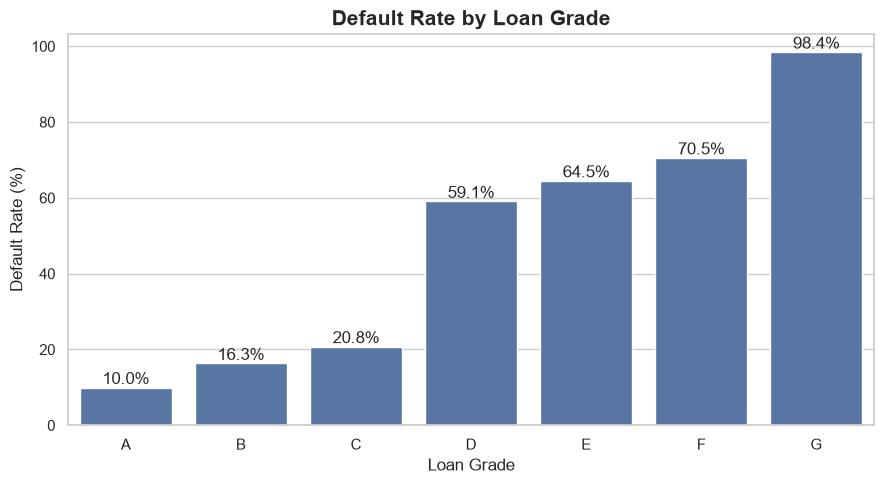

In [31]:
grade_default = (
    df.groupby("loan_grade", observed=False)["loan_status"]
      .mean()
      .mul(100)
      .reset_index(name="default_rate")
)

grade_order = sorted(df["loan_grade"].dropna().unique())

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=grade_default,
    x="loan_grade",
    y="default_rate",
    order=grade_order
)
plt.title("Default Rate by Loan Grade", fontsize=15, fontweight="bold")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


# 9.7 Loan Grade vs Interest Rate

### Question
How does interest rate vary across loan grades?


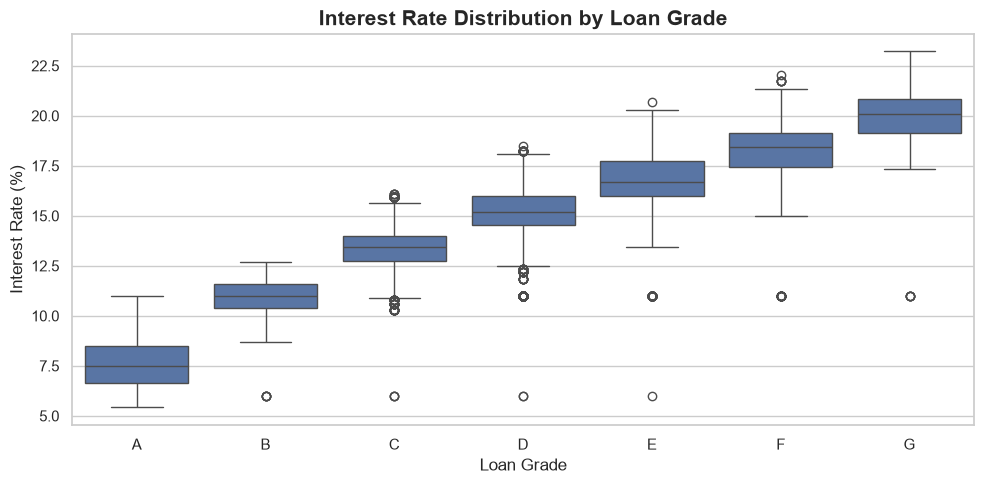

In [32]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="loan_grade", y="loan_int_rate", order=grade_order)
plt.title("Interest Rate Distribution by Loan Grade", fontsize=15, fontweight="bold")
plt.xlabel("Loan Grade")
plt.ylabel("Interest Rate (%)")
plt.tight_layout()
plt.show()


# 9.8 Loan Amount Analysis

### Question
How are requested loan amounts distributed?


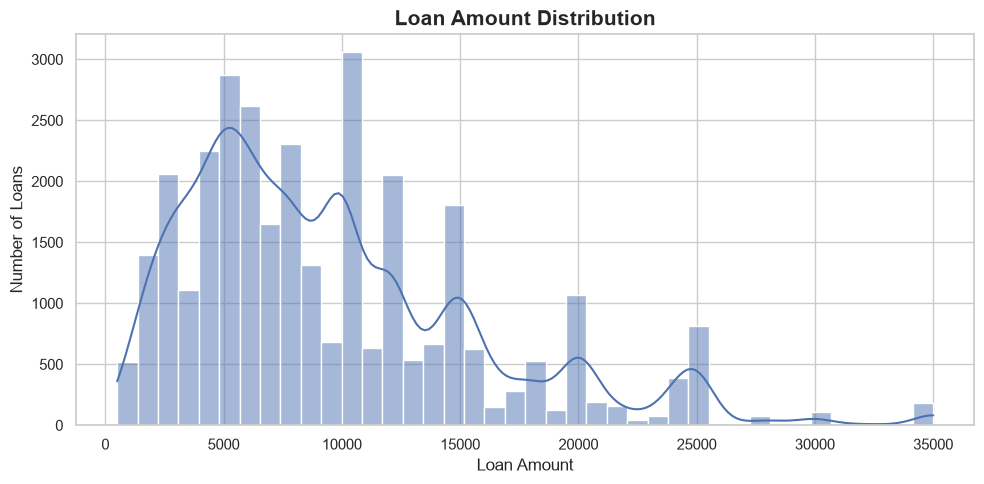

In [33]:
plt.figure(figsize=(10, 5))
sns.histplot(df["loan_amnt"], bins=40, kde=True)
plt.title("Loan Amount Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.show()


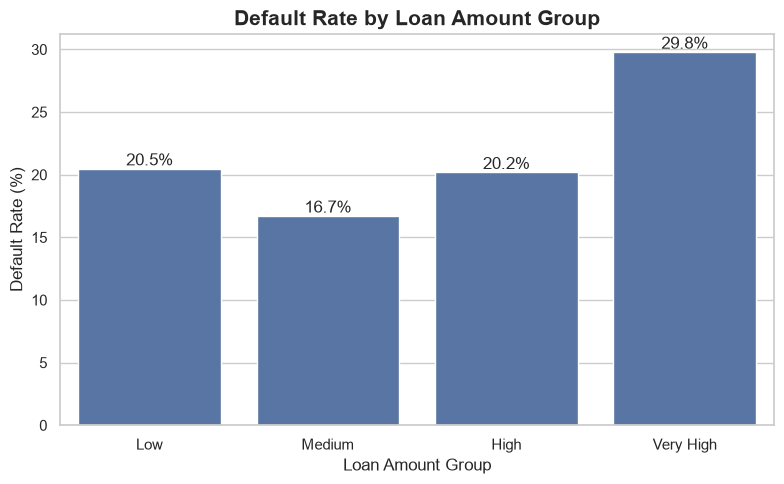

In [34]:
loan_group_default = (
    df.groupby("loan_amount_group", observed=False)["loan_status"]
      .mean()
      .mul(100)
      .reset_index(name="default_rate")
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=loan_group_default, x="loan_amount_group", y="default_rate")
plt.title("Default Rate by Loan Amount Group", fontsize=15, fontweight="bold")
plt.xlabel("Loan Amount Group")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


# 9.9 Loan Amount vs Income

### Question
Does loan size increase with borrower income?


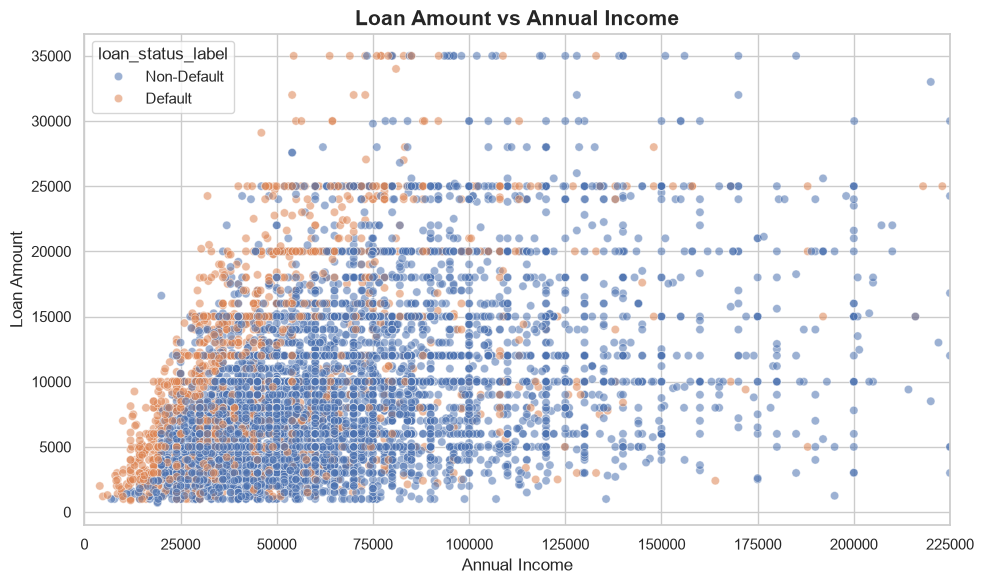

In [35]:
sample_df = df.sample(min(8000, len(df)), random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_df,
    x="person_income",
    y="loan_amnt",
    hue="loan_status_label",
    alpha=0.55
)
plt.title("Loan Amount vs Annual Income", fontsize=15, fontweight="bold")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")
plt.xlim(0, df["person_income"].quantile(0.99))
plt.tight_layout()
plt.show()


# 9.10 Loan-to-Income Burden

### Question
How does loan burden relate to observed default?


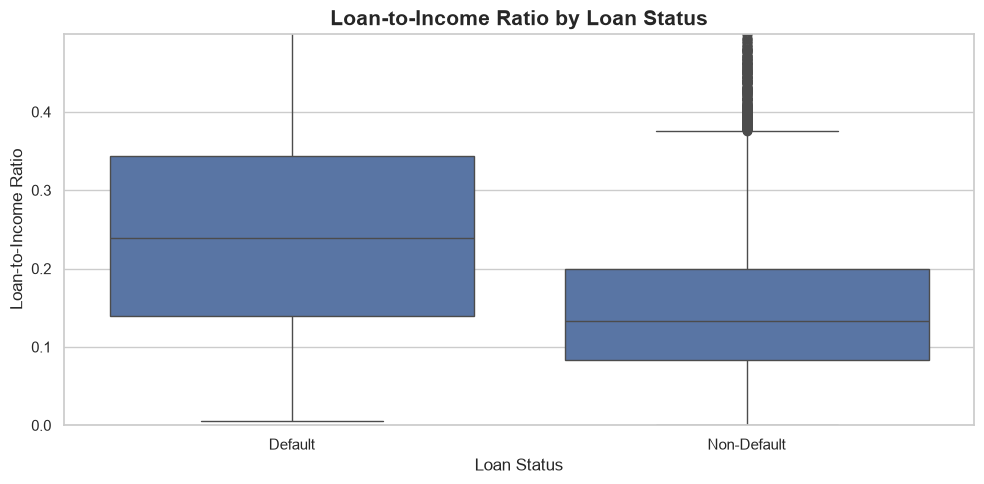

In [36]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="loan_status_label", y="loan_to_income")
plt.title("Loan-to-Income Ratio by Loan Status", fontsize=15, fontweight="bold")
plt.xlabel("Loan Status")
plt.ylabel("Loan-to-Income Ratio")
plt.ylim(0, df["loan_to_income"].quantile(0.99))
plt.tight_layout()
plt.show()


In [37]:
burden_summary = (
    df.groupby("loan_status_label")["loan_to_income"]
      .agg(["mean", "median"])
      .round(3)
)

display(burden_summary)


,mean,median
loan_status_label,,
Default,0.25,0.24
Non-Default,0.15,0.13


# 9.11 Interest Rate Analysis

### Question
Is observed default rate different across interest-rate bands?


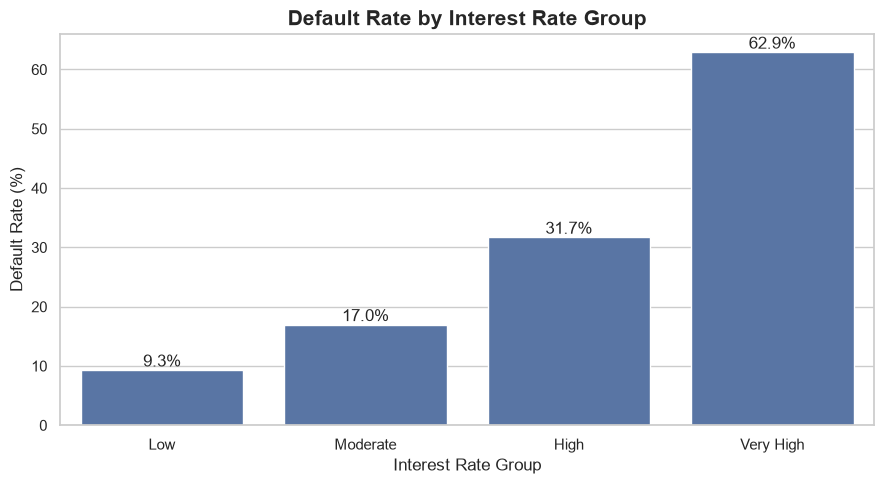

In [38]:
rate_default = (
    df.groupby("interest_rate_group", observed=False)["loan_status"]
      .mean()
      .mul(100)
      .reset_index(name="default_rate")
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=rate_default, x="interest_rate_group", y="default_rate")
plt.title("Default Rate by Interest Rate Group", fontsize=15, fontweight="bold")
plt.xlabel("Interest Rate Group")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


# 9.12 Previous Credit Default History

### Question
How does a previous recorded credit default relate to current loan status?


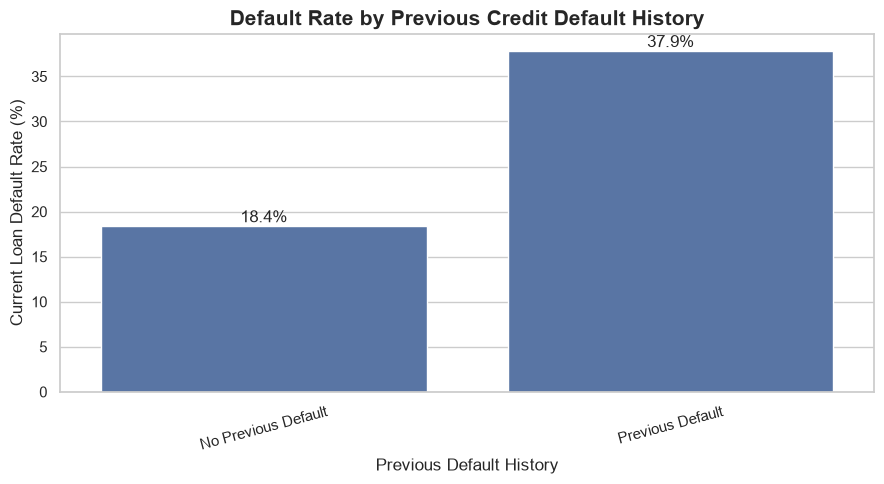

In [39]:
previous_default = (
    df.groupby("previous_default_label")["loan_status"]
      .mean()
      .mul(100)
      .reset_index(name="default_rate")
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=previous_default, x="previous_default_label", y="default_rate")
plt.title("Default Rate by Previous Credit Default History", fontsize=15, fontweight="bold")
plt.xlabel("Previous Default History")
plt.ylabel("Current Loan Default Rate (%)")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


# 9.13 Credit History Length

### Question
Does credit history length differ between default and non-default groups?


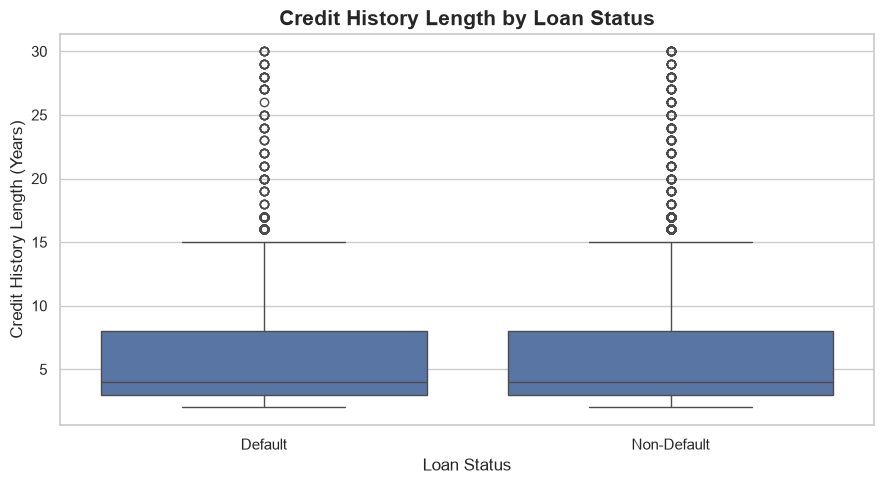

In [40]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="loan_status_label", y="cb_person_cred_hist_length")
plt.title("Credit History Length by Loan Status", fontsize=15, fontweight="bold")
plt.xlabel("Loan Status")
plt.ylabel("Credit History Length (Years)")
plt.tight_layout()
plt.show()


# 9.14 Employment Length

### Question
How does employment length vary across default status?


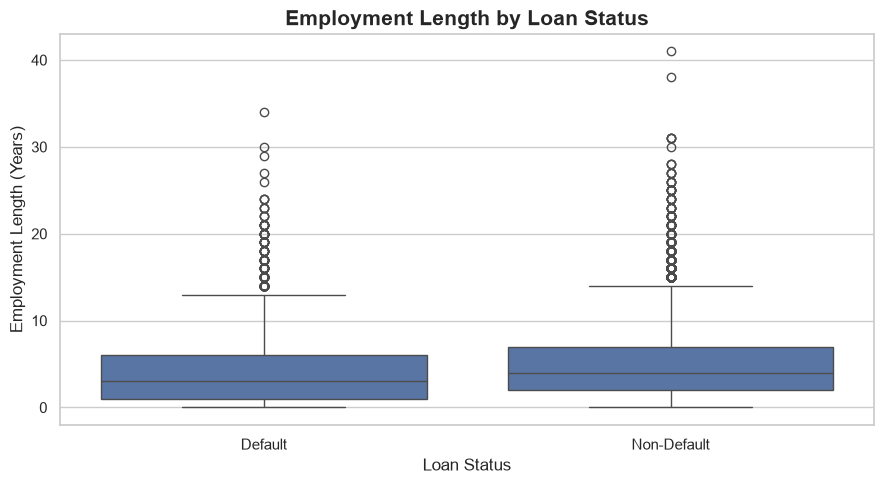

In [41]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="loan_status_label", y="person_emp_length")
plt.title("Employment Length by Loan Status", fontsize=15, fontweight="bold")
plt.xlabel("Loan Status")
plt.ylabel("Employment Length (Years)")
plt.tight_layout()
plt.show()


# 10. Multivariate Analysis

We now combine multiple dimensions to identify patterns that are not obvious from one variable at a time.


## Loan Grade × Previous Default History

This cross-analysis helps compare observed default rates across two credit-related dimensions.


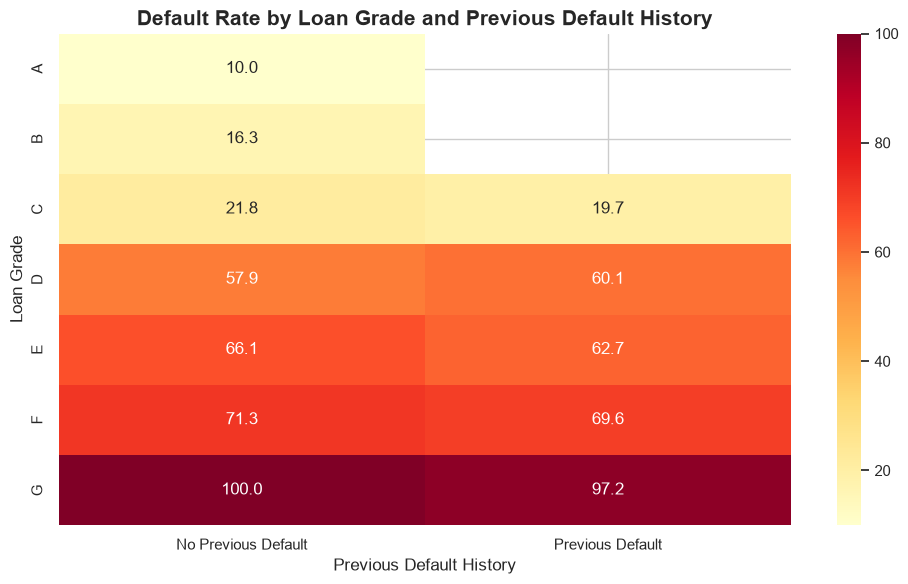

In [42]:
pivot_grade_history = pd.pivot_table(
    df,
    values="loan_status",
    index="loan_grade",
    columns="previous_default_label",
    aggfunc="mean"
) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_grade_history, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Default Rate by Loan Grade and Previous Default History", fontsize=15, fontweight="bold")
plt.xlabel("Previous Default History")
plt.ylabel("Loan Grade")
plt.tight_layout()
plt.show()


## Loan Purpose × Home Ownership

Compare the observed default rate across combinations of loan purpose and home ownership.


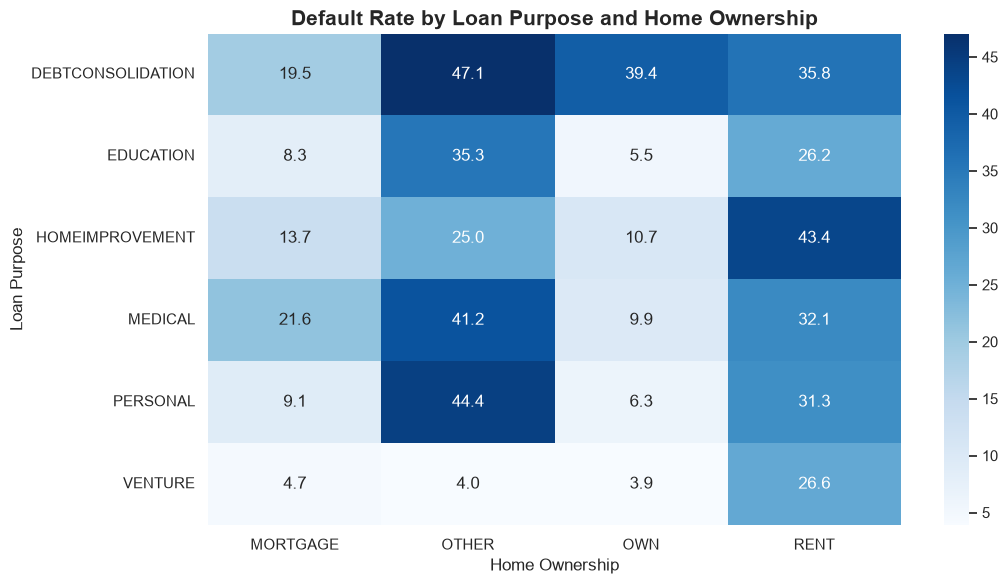

In [43]:
pivot_purpose_home = pd.pivot_table(
    df,
    values="loan_status",
    index="loan_intent",
    columns="person_home_ownership",
    aggfunc="mean"
) * 100

plt.figure(figsize=(11, 6))
sns.heatmap(pivot_purpose_home, annot=True, fmt=".1f", cmap="Blues")
plt.title("Default Rate by Loan Purpose and Home Ownership", fontsize=15, fontweight="bold")
plt.xlabel("Home Ownership")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()


# 11. Correlation Analysis

Correlation measures linear association between numerical variables. It should not be interpreted as proof of causation.


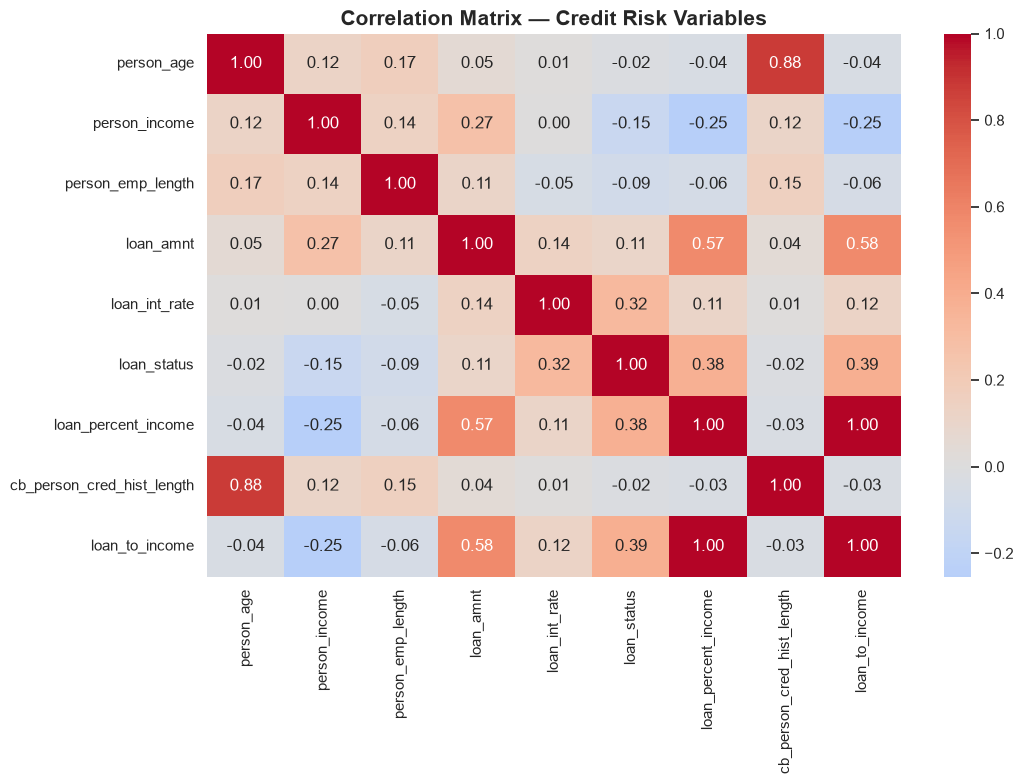

In [44]:
numeric_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_status",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "loan_to_income"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix — Credit Risk Variables", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


# 12. Key Business Metrics

A compact summary of the most important lending indicators.


In [45]:
overall_default_rate = df["loan_status"].mean() * 100
avg_loan = df["loan_amnt"].mean()
avg_income = df["person_income"].mean()
avg_interest = df["loan_int_rate"].mean()
median_loan = df["loan_amnt"].median()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Loan Records",
        "Overall Default Rate",
        "Average Loan Amount",
        "Median Loan Amount",
        "Average Annual Income",
        "Average Interest Rate"
    ],
    "Value": [
        len(df),
        f"{overall_default_rate:.2f}%",
        f"${avg_loan:,.0f}",
        f"${median_loan:,.0f}",
        f"${avg_income:,.0f}",
        f"{avg_interest:.2f}%"
    ]
})

display(kpi_summary)


,Metric,Value
0,Total Loan Records,32416
1,Overall Default Rate,21.87%
2,Average Loan Amount,"$9,594"
3,Median Loan Amount,"$8,000"
4,Average Annual Income,"$66,092"
5,Average Interest Rate,11.01%


# 13. Business Insights

Use the following code to generate a compact ranking of segment-level default rates. The actual values are calculated directly from the cleaned dataset.


In [46]:
print("Highest observed default-rate loan purposes:")
display(
    purpose_default.sort_values("default_rate", ascending=False)
    .reset_index(drop=True)
)

print("Highest observed default-rate loan grades:")
display(
    grade_default.sort_values("default_rate", ascending=False)
    .reset_index(drop=True)
)

print("Default rate by previous credit default history:")
display(previous_default.sort_values("default_rate", ascending=False))


Highest observed default-rate loan purposes:


,loan_intent,default_rate,count
0,DEBTCONSOLIDATION,28.68,5189
1,MEDICAL,26.76,6042
2,HOMEIMPROVEMENT,26.15,3594
3,PERSONAL,19.90,5498
4,EDUCATION,17.25,6411
5,VENTURE,14.85,5682


Highest observed default-rate loan grades:


,loan_grade,default_rate
0,G,98.44
1,F,70.54
2,E,64.49
3,D,59.06
4,C,20.75
5,B,16.32
6,A,9.96


Default rate by previous credit default history:


,previous_default_label,default_rate
1,Previous Default,37.87
0,No Previous Default,18.43


In [49]:
# ============================================================
# DIGITAL LENDING & CREDIT RISK DASHBOARD
# Gradio + Pandas + Plotly
# ============================================================

import gradio as gr
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go


# ============================================================
# CONFIGURATION
# ============================================================

DEFAULT_FILE = "credit_risk_dataset.csv"

BG = "#0B1020"
CARD = "#111827"
CARD_2 = "#172033"
TEXT = "#F8FAFC"
MUTED = "#94A3B8"
BORDER = "#263244"

ACCENT = "#38BDF8"
GREEN = "#34D399"
RED = "#F87171"
YELLOW = "#FBBF24"


# ============================================================
# LOAD + CLEAN DATA
# ============================================================

def prepare_data(df):

    df = df.copy()

    # --------------------------------------------------------
    # Remove duplicates
    # --------------------------------------------------------

    df = df.drop_duplicates().copy()

    # --------------------------------------------------------
    # Numeric columns
    # --------------------------------------------------------

    numeric_columns = [
        "person_age",
        "person_income",
        "person_emp_length",
        "loan_amnt",
        "loan_int_rate",
        "loan_status",
        "loan_percent_income",
        "cb_person_cred_hist_length"
    ]

    for col in numeric_columns:

        if col in df.columns:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

    # --------------------------------------------------------
    # Invalid observations
    # Based on the original EDA notebook
    # --------------------------------------------------------

    if "person_age" in df.columns:

        df.loc[
            df["person_age"] > 100,
            "person_age"
        ] = np.nan

    if "person_emp_length" in df.columns:

        df.loc[
            df["person_emp_length"] > 50,
            "person_emp_length"
        ] = np.nan

    # --------------------------------------------------------
    # Median imputation
    # --------------------------------------------------------

    for col in [
        "person_age",
        "person_emp_length",
        "loan_int_rate"
    ]:

        if col in df.columns:

            df[col] = df[col].fillna(
                df[col].median()
            )

    # --------------------------------------------------------
    # Feature Engineering
    # Same logic as notebook
    # --------------------------------------------------------

    if {
        "loan_amnt",
        "person_income"
    }.issubset(df.columns):

        df["loan_to_income"] = (
            df["loan_amnt"] /
            df["person_income"].replace(0, np.nan)
        )

    if "person_income" in df.columns:

        df["income_lakh"] = (
            df["person_income"] / 100000
        )

    if "loan_amnt" in df.columns:

        df["loan_amount_k"] = (
            df["loan_amnt"] / 1000
        )

    # --------------------------------------------------------
    # Loan Status Label
    # --------------------------------------------------------

    if "loan_status" in df.columns:

        df["loan_status_label"] = (
            df["loan_status"]
            .map({
                0: "Non-Default",
                1: "Default"
            })
            .fillna("Unknown")
        )

    # --------------------------------------------------------
    # Previous Default Label
    # --------------------------------------------------------

    if "cb_person_default_on_file" in df.columns:

        df["previous_default_label"] = (
            df["cb_person_default_on_file"]
            .map({
                "N": "No Previous Default",
                "Y": "Previous Default"
            })
            .fillna("Unknown")
        )

    # --------------------------------------------------------
    # Age Groups
    # --------------------------------------------------------

    if "person_age" in df.columns:

        df["age_group"] = pd.cut(
            df["person_age"],
            bins=[17, 25, 35, 45, 55, 100],
            labels=[
                "18-25",
                "26-35",
                "36-45",
                "46-55",
                "56+"
            ]
        )

    # --------------------------------------------------------
    # Income Groups
    # --------------------------------------------------------

    if "person_income" in df.columns:

        try:

            df["income_group"] = pd.qcut(
                df["person_income"],
                q=4,
                labels=[
                    "Low",
                    "Medium",
                    "High",
                    "Very High"
                ],
                duplicates="drop"
            )

        except:

            df["income_group"] = "Unknown"

    # --------------------------------------------------------
    # Loan Amount Groups
    # --------------------------------------------------------

    if "loan_amnt" in df.columns:

        try:

            df["loan_amount_group"] = pd.qcut(
                df["loan_amnt"],
                q=4,
                labels=[
                    "Low",
                    "Medium",
                    "High",
                    "Very High"
                ],
                duplicates="drop"
            )

        except:

            df["loan_amount_group"] = "Unknown"

    # --------------------------------------------------------
    # Interest Rate Groups
    # Same as notebook
    # --------------------------------------------------------

    if "loan_int_rate" in df.columns:

        df["interest_rate_group"] = pd.cut(
            df["loan_int_rate"],
            bins=[0, 8, 12, 16, 25],
            labels=[
                "Low",
                "Moderate",
                "High",
                "Very High"
            ]
        )

    return df


# ============================================================
# LOAD INITIAL DATA
# ============================================================

try:

    initial_df = pd.read_csv(
        DEFAULT_FILE
    )

    initial_df = prepare_data(
        initial_df
    )

    print(
        f"Initial dataset loaded: "
        f"{len(initial_df):,} rows"
    )

except Exception as e:

    print(
        "Default CSV not found."
    )

    print(
        "Upload the CSV using the dashboard."
    )

    initial_df = pd.DataFrame()


# ============================================================
# HELPER — EMPTY FIGURE
# ============================================================

def empty_figure(
    message="No data available"
):

    fig = go.Figure()

    fig.add_annotation(
        text=message,
        x=0.5,
        y=0.5,
        xref="paper",
        yref="paper",
        showarrow=False,
        font=dict(
            size=18,
            color=MUTED
        )
    )

    fig.update_layout(
        template="plotly_dark",
        paper_bgcolor=CARD,
        plot_bgcolor=CARD,
        xaxis=dict(
            visible=False
        ),
        yaxis=dict(
            visible=False
        )
    )

    return fig


# ============================================================
# HELPER — STYLE FIGURE
# ============================================================

def style_fig(
    fig,
    title
):

    fig.update_layout(

        template="plotly_dark",

        paper_bgcolor=CARD,

        plot_bgcolor=CARD,

        font=dict(
            color=TEXT,
            family="Arial"
        ),

        title=dict(
            text=title,
            font=dict(
                size=18,
                color=TEXT
            )
        ),

        margin=dict(
            l=50,
            r=30,
            t=70,
            b=60
        ),

        legend=dict(
            bgcolor="rgba(0,0,0,0)"
        )
    )

    fig.update_xaxes(
        gridcolor=BORDER,
        zerolinecolor=BORDER
    )

    fig.update_yaxes(
        gridcolor=BORDER,
        zerolinecolor=BORDER
    )

    return fig


# ============================================================
# KPI CARD
# ============================================================

def kpi_card(
    title,
    value,
    subtitle="",
    accent=ACCENT
):

    return f"""

    <div style="
        background:{CARD};
        border:1px solid {BORDER};
        border-radius:16px;
        padding:20px;
        min-height:120px;
        box-shadow:0 8px 25px rgba(0,0,0,0.15);
    ">

        <div style="
            color:{MUTED};
            font-size:12px;
            font-weight:600;
            text-transform:uppercase;
            letter-spacing:1px;
        ">

            {title}

        </div>

        <div style="
            color:{accent};
            font-size:29px;
            font-weight:800;
            margin-top:10px;
        ">

            {value}

        </div>

        <div style="
            color:{MUTED};
            font-size:12px;
            margin-top:7px;
        ">

            {subtitle}

        </div>

    </div>

    """


# ============================================================
# FILTER DATA
# ============================================================

def filter_data(
    df,
    home_ownership,
    loan_intent,
    loan_grade,
    loan_status,
    previous_default
):

    if df is None or len(df) == 0:

        return pd.DataFrame()

    data = df.copy()

    # --------------------------------------------------------
    # Home Ownership
    # --------------------------------------------------------

    if (
        home_ownership
        and "All" not in home_ownership
        and "person_home_ownership" in data.columns
    ):

        data = data[
            data[
                "person_home_ownership"
            ].astype(str).isin(
                home_ownership
            )
        ]

    # --------------------------------------------------------
    # Loan Purpose
    # --------------------------------------------------------

    if (
        loan_intent
        and "All" not in loan_intent
        and "loan_intent" in data.columns
    ):

        data = data[
            data[
                "loan_intent"
            ].astype(str).isin(
                loan_intent
            )
        ]

    # --------------------------------------------------------
    # Loan Grade
    # --------------------------------------------------------

    if (
        loan_grade
        and "All" not in loan_grade
        and "loan_grade" in data.columns
    ):

        data = data[
            data[
                "loan_grade"
            ].astype(str).isin(
                loan_grade
            )
        ]

    # --------------------------------------------------------
    # Loan Status
    # --------------------------------------------------------

    if (
        loan_status
        and loan_status != "All"
        and "loan_status_label" in data.columns
    ):

        data = data[
            data[
                "loan_status_label"
            ] == loan_status
        ]

    # --------------------------------------------------------
    # Previous Default
    # --------------------------------------------------------

    if (
        previous_default
        and previous_default != "All"
        and "previous_default_label" in data.columns
    ):

        data = data[
            data[
                "previous_default_label"
            ] == previous_default
        ]

    return data


# ============================================================
# FILTER OPTIONS
# ============================================================

def get_choices(
    df,
    column
):

    if column not in df.columns:

        return ["All"]

    values = (

        df[column]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
        .tolist()

    )

    values = sorted(values)

    return ["All"] + values


# ============================================================
# LOAD DATASET + UPDATE FILTERS
# ============================================================

def load_dataset(
    file
):

    # --------------------------------------------------------
    # No uploaded file
    # --------------------------------------------------------

    if file is None:

        if len(initial_df) > 0:

            df = initial_df.copy()

        else:

            return (
                pd.DataFrame(),
                gr.update(
                    choices=["All"],
                    value=["All"]
                ),
                gr.update(
                    choices=["All"],
                    value=["All"]
                ),
                gr.update(
                    choices=["All"],
                    value=["All"]
                ),
                "⚠️ Please upload a CSV dataset."
            )

    # --------------------------------------------------------
    # Uploaded file
    # IMPORTANT:
    # type="filepath" gives a STRING PATH
    # --------------------------------------------------------

    else:

        try:

            df = pd.read_csv(
                file
            )

        except Exception as e:

            print(
                "CSV loading error:",
                e
            )

            return (
                pd.DataFrame(),
                gr.update(
                    choices=["All"],
                    value=["All"]
                ),
                gr.update(
                    choices=["All"],
                    value=["All"]
                ),
                gr.update(
                    choices=["All"],
                    value=["All"]
                ),
                f"❌ Error loading CSV: {e}"
            )

    # --------------------------------------------------------
    # Prepare data
    # --------------------------------------------------------

    df = prepare_data(
        df
    )

    print(
        "\nDataset loaded successfully."
    )

    print(
        "Rows:",
        len(df)
    )

    print(
        "Columns:",
        df.columns.tolist()
    )

    print(
        "Home Ownership:",
        get_choices(
            df,
            "person_home_ownership"
        )
    )

    print(
        "Loan Purpose:",
        get_choices(
            df,
            "loan_intent"
        )
    )

    print(
        "Loan Grade:",
        get_choices(
            df,
            "loan_grade"
        )
    )

    return (

        df,

        gr.update(
            choices=get_choices(
                df,
                "person_home_ownership"
            ),
            value=["All"]
        ),

        gr.update(
            choices=get_choices(
                df,
                "loan_intent"
            ),
            value=["All"]
        ),

        gr.update(
            choices=get_choices(
                df,
                "loan_grade"
            ),
            value=["All"]
        ),

        f"✅ Dataset loaded successfully — "
        f"{len(df):,} rows"
    )


# ============================================================
# MAIN DASHBOARD FUNCTION
# ============================================================

def update_dashboard(

    df,

    home_ownership,

    loan_intent,

    loan_grade,

    loan_status,

    previous_default

):

    # ========================================================
    # EMPTY DATA
    # ========================================================

    if df is None or len(df) == 0:

        blank = empty_figure(
            "No dataset loaded"
        )

        return (

            kpi_card(
                "Total Loans",
                "0"
            ),

            kpi_card(
                "Default Rate",
                "0%"
            ),

            kpi_card(
                "Average Loan",
                "$0"
            ),

            kpi_card(
                "Average Income",
                "$0"
            ),

            kpi_card(
                "Avg Interest",
                "0%"
            ),

            kpi_card(
                "Loan-to-Income",
                "0%"
            ),

            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,

            pd.DataFrame()
        )

    # ========================================================
    # APPLY FILTERS
    # ========================================================

    data = filter_data(

        df,

        home_ownership,

        loan_intent,

        loan_grade,

        loan_status,

        previous_default

    )

    # ========================================================
    # NO RECORDS AFTER FILTER
    # ========================================================

    if len(data) == 0:

        blank = empty_figure(
            "No records match the selected filters"
        )

        return (

            kpi_card(
                "Total Loans",
                "0"
            ),

            kpi_card(
                "Default Rate",
                "0%"
            ),

            kpi_card(
                "Average Loan",
                "$0"
            ),

            kpi_card(
                "Average Income",
                "$0"
            ),

            kpi_card(
                "Avg Interest",
                "0%"
            ),

            kpi_card(
                "Loan-to-Income",
                "0%"
            ),

            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,
            blank,

            pd.DataFrame()
        )

    # ========================================================
    # KPI CALCULATIONS
    # ========================================================

    total_loans = len(data)

    default_rate = (
        data["loan_status"].mean() * 100
        if "loan_status" in data.columns
        else 0
    )

    avg_loan = (
        data["loan_amnt"].mean()
        if "loan_amnt" in data.columns
        else 0
    )

    avg_income = (
        data["person_income"].mean()
        if "person_income" in data.columns
        else 0
    )

    avg_interest = (
        data["loan_int_rate"].mean()
        if "loan_int_rate" in data.columns
        else 0
    )

    avg_lti = (
        data["loan_to_income"].mean() * 100
        if "loan_to_income" in data.columns
        else 0
    )

    # ========================================================
    # 1. DEFAULT DISTRIBUTION
    # ========================================================

    status_counts = (
        data[
            "loan_status_label"
        ]
        .value_counts()
        .reset_index()
    )

    status_counts.columns = [
        "Loan Status",
        "Count"
    ]

    fig_status = px.pie(

        status_counts,

        names="Loan Status",

        values="Count",

        hole=0.60

    )

    fig_status.update_traces(
        textinfo="percent+label"
    )

    style_fig(
        fig_status,
        "Loan Default Distribution"
    )

    # ========================================================
    # 2. DEFAULT RATE BY LOAN PURPOSE
    # ========================================================

    purpose = (

        data
        .groupby(
            "loan_intent"
        )["loan_status"]
        .mean()
        .mul(100)
        .reset_index()

    )

    purpose.columns = [
        "Loan Purpose",
        "Default Rate"
    ]

    purpose = purpose.sort_values(
        "Default Rate",
        ascending=False
    )

    fig_purpose = px.bar(

        purpose,

        x="Loan Purpose",

        y="Default Rate",

        text_auto=".1f"

    )

    style_fig(
        fig_purpose,
        "Default Rate by Loan Purpose"
    )

    # ========================================================
    # 3. DEFAULT RATE BY LOAN GRADE
    # ========================================================

    grade = (

        data
        .groupby(
            "loan_grade"
        )["loan_status"]
        .mean()
        .mul(100)
        .reset_index()

    )

    grade.columns = [
        "Loan Grade",
        "Default Rate"
    ]

    grade_order = [
        "A",
        "B",
        "C",
        "D",
        "E",
        "F",
        "G"
    ]

    grade["Loan Grade"] = pd.Categorical(

        grade["Loan Grade"],

        categories=grade_order,

        ordered=True

    )

    grade = grade.sort_values(
        "Loan Grade"
    )

    fig_grade = px.bar(

        grade,

        x="Loan Grade",

        y="Default Rate",

        text_auto=".1f"

    )

    style_fig(
        fig_grade,
        "Default Rate by Loan Grade"
    )

    # ========================================================
    # 4. INCOME VS LOAN AMOUNT
    # ========================================================

    scatter_data = data.copy()

    if len(scatter_data) > 5000:

        scatter_data = scatter_data.sample(
            5000,
            random_state=42
        )

    fig_income_loan = px.scatter(

        scatter_data,

        x="person_income",

        y="loan_amnt",

        color="loan_status_label",

        hover_data=[
            "person_age",
            "loan_grade",
            "loan_intent"
        ],

        opacity=0.65

    )

    style_fig(
        fig_income_loan,
        "Borrower Income vs Loan Amount"
    )

    # ========================================================
    # 5. AGE ANALYSIS
    # ========================================================

    age = (

        data
        .groupby(
            "age_group",
            observed=False
        )["loan_status"]
        .mean()
        .mul(100)
        .reset_index()

    )

    age.columns = [
        "Age Group",
        "Default Rate"
    ]

    fig_age = px.bar(

        age,

        x="Age Group",

        y="Default Rate",

        text_auto=".1f"

    )

    style_fig(
        fig_age,
        "Default Rate by Age Group"
    )

    # ========================================================
    # 6. INCOME GROUP ANALYSIS
    # ========================================================

    income = (

        data
        .groupby(
            "income_group",
            observed=False
        )["loan_status"]
        .mean()
        .mul(100)
        .reset_index()

    )

    income.columns = [
        "Income Group",
        "Default Rate"
    ]

    fig_income = px.bar(

        income,

        x="Income Group",

        y="Default Rate",

        text_auto=".1f"

    )

    style_fig(
        fig_income,
        "Default Rate by Income Group"
    )

    # ========================================================
    # 7. PREVIOUS DEFAULT
    # ========================================================

    previous = (

        data
        .groupby(
            "previous_default_label"
        )["loan_status"]
        .mean()
        .mul(100)
        .reset_index()

    )

    previous.columns = [
        "Previous Default History",
        "Default Rate"
    ]

    fig_previous = px.bar(

        previous,

        x="Previous Default History",

        y="Default Rate",

        text_auto=".1f"

    )

    style_fig(
        fig_previous,
        "Default Rate by Previous Credit Default"
    )

    # ========================================================
    # 8. EMPLOYMENT LENGTH
    # ========================================================

    fig_employment = px.box(

        data,

        x="loan_status_label",

        y="person_emp_length"

    )

    style_fig(
        fig_employment,
        "Employment Length by Loan Status"
    )

    # ========================================================
    # 9. LOAN-TO-INCOME
    # ========================================================

    fig_burden = px.box(

        data,

        x="loan_status_label",

        y="loan_to_income"

    )

    style_fig(
        fig_burden,
        "Loan-to-Income Ratio by Loan Status"
    )

    # Remove extreme visual outliers
    # without changing underlying data

    if len(data) > 0:

        upper_limit = (
            data["loan_to_income"]
            .quantile(0.99)
        )

        fig_burden.update_yaxes(
            range=[
                0,
                upper_limit
            ]
        )

    # ========================================================
    # 10. INTEREST RATE
    # ========================================================

    rate = (

        data
        .groupby(
            "interest_rate_group",
            observed=False
        )["loan_status"]
        .mean()
        .mul(100)
        .reset_index()

    )

    rate.columns = [
        "Interest Rate Group",
        "Default Rate"
    ]

    fig_rate = px.bar(

        rate,

        x="Interest Rate Group",

        y="Default Rate",

        text_auto=".1f"

    )

    style_fig(
        fig_rate,
        "Default Rate by Interest Rate Group"
    )

    # ========================================================
    # 11. LOAN GRADE RISK
    # ========================================================

    # This is a separate chart specifically for
    # Loan Analysis

    grade_risk = (

        data
        .groupby(
            "loan_grade"
        )
        .agg(
            default_rate=(
                "loan_status",
                "mean"
            ),

            loan_count=(
                "loan_status",
                "count"
            )
        )
        .reset_index()

    )

    grade_risk[
        "default_rate"
    ] *= 100

    grade_risk = grade_risk.sort_values(
        "default_rate",
        ascending=False
    )

    fig_grade_risk = px.bar(

        grade_risk,

        x="loan_grade",

        y="default_rate",

        text="default_rate",

        hover_data=[
            "loan_count"
        ]

    )

    fig_grade_risk.update_traces(
        texttemplate="%{text:.1f}%",
        textposition="outside"
    )

    style_fig(
        fig_grade_risk,
        "Loan Grade Risk"
    )

    # ========================================================
    # 12. LOAN PURPOSE RISK
    # ========================================================

    purpose_risk = (

        data
        .groupby(
            "loan_intent"
        )
        .agg(
            default_rate=(
                "loan_status",
                "mean"
            ),

            loan_count=(
                "loan_status",
                "count"
            )
        )
        .reset_index()

    )

    purpose_risk[
        "default_rate"
    ] *= 100

    purpose_risk = purpose_risk.sort_values(
        "default_rate",
        ascending=False
    )

    fig_purpose_risk = px.bar(

        purpose_risk,

        x="loan_intent",

        y="default_rate",

        text="default_rate",

        hover_data=[
            "loan_count"
        ]

    )

    fig_purpose_risk.update_traces(
        texttemplate="%{text:.1f}%",
        textposition="outside"
    )

    style_fig(
        fig_purpose_risk,
        "Loan Purpose Risk"
    )

    # ========================================================
    # 13. GRADE × PREVIOUS DEFAULT
    # ========================================================

    pivot_grade = pd.pivot_table(

        data,

        values="loan_status",

        index="loan_grade",

        columns="previous_default_label",

        aggfunc="mean"

    ) * 100

    fig_heat_grade = px.imshow(

        pivot_grade,

        text_auto=".1f",

        aspect="auto",

        color_continuous_scale="YlOrRd"

    )

    style_fig(
        fig_heat_grade,
        "Default Rate by Loan Grade & Previous Default"
    )

    # ========================================================
    # 14. PURPOSE × HOME OWNERSHIP
    # ========================================================

    pivot_home = pd.pivot_table(

        data,

        values="loan_status",

        index="loan_intent",

        columns="person_home_ownership",

        aggfunc="mean"

    ) * 100

    fig_heat_home = px.imshow(

        pivot_home,

        text_auto=".1f",

        aspect="auto",

        color_continuous_scale="Blues"

    )

    style_fig(
        fig_heat_home,
        "Default Rate by Loan Purpose & Home Ownership"
    )

    # ========================================================
    # DATA TABLE
    # ========================================================

    display_columns = [

        "person_age",

        "person_income",

        "person_home_ownership",

        "person_emp_length",

        "loan_intent",

        "loan_grade",

        "loan_amnt",

        "loan_int_rate",

        "loan_status_label",

        "loan_percent_income",

        "cb_person_default_on_file",

        "cb_person_cred_hist_length"

    ]

    display_columns = [

        col

        for col in display_columns

        if col in data.columns

    ]

    table = data[
        display_columns
    ].copy()

    # ========================================================
    # IMPORTANT:
    # RETURN ORDER MUST EXACTLY MATCH GRADIO OUTPUT ORDER
    # ========================================================

    return (

        # ---------------- KPI ----------------

        kpi_card(
            "Total Loans",
            f"{total_loans:,}",
            "Records after filters"
        ),

        kpi_card(
            "Default Rate",
            f"{default_rate:.2f}%",
            "Observed default rate",
            RED if default_rate > 20 else GREEN
        ),

        kpi_card(
            "Average Loan",
            f"${avg_loan:,.0f}",
            "Mean loan amount"
        ),

        kpi_card(
            "Average Income",
            f"${avg_income:,.0f}",
            "Annual borrower income"
        ),

        kpi_card(
            "Avg Interest",
            f"{avg_interest:.2f}%",
            "Average interest rate",
            YELLOW
        ),

        kpi_card(
            "Loan-to-Income",
            f"{avg_lti:.2f}%",
            "Average loan burden"
        ),

        # ---------------- OVERVIEW ----------------

        fig_status,

        fig_purpose,

        fig_grade,

        fig_income_loan,

        # ---------------- BORROWER ----------------

        fig_age,

        fig_income,

        fig_previous,

        fig_employment,

        # ---------------- LOAN ----------------

        fig_burden,

        fig_rate,

        fig_grade_risk,

        fig_purpose_risk,

        # ---------------- CREDIT RISK ----------------

        fig_heat_grade,

        fig_heat_home,

        # ---------------- DATA ----------------

        table
    )


# ============================================================
# CSS
# ============================================================

CSS = """

body {
    background: #0B1020 !important;
}

.gradio-container {
    max-width: 1600px !important;
    background: #0B1020 !important;
}

#dashboard-title {
    text-align: center;
    padding: 25px 0 15px 0;
}

#dashboard-title h1 {
    font-size: 36px;
    font-weight: 800;
    color: #F8FAFC;
    margin-bottom: 5px;
}

#dashboard-title p {
    color: #94A3B8;
    font-size: 15px;
}

.section-title {
    color: #F8FAFC;
    font-size: 22px;
    font-weight: 700;
    margin: 20px 0 12px 0;
}

.filter-box {
    background: #111827;
    border: 1px solid #263244;
    border-radius: 16px;
    padding: 18px;
}

.status-box {
    text-align: center;
    color: #94A3B8;
    font-size: 13px;
    padding: 5px;
}

footer {
    display: none !important;
}

"""


# ============================================================
# GRADIO APPLICATION
# ============================================================

with gr.Blocks(

    title="Digital Lending & Credit Risk Dashboard",

    css=CSS,

    theme=gr.themes.Base(
        primary_hue="sky",
        secondary_hue="slate",
        neutral_hue="slate"
    )

) as app:

    # ========================================================
    # HEADER
    # ========================================================

    gr.HTML("""

    <div id="dashboard-title">

        <h1>
            💳 Digital Lending & Credit Risk Dashboard
        </h1>

        <p>
            Borrower Profile • Loan Behaviour • Default Risk •
            Credit History • Portfolio Analysis
        </p>

    </div>

    """)

    # ========================================================
    # FILE UPLOAD
    # ========================================================

    with gr.Row():

        file_input = gr.File(

            label="Upload Credit Risk CSV",

            file_types=[
                ".csv"
            ],

            type="filepath"

        )

        load_button = gr.Button(

            "🔄 Load Dataset",

            variant="primary"

        )

    dataset_status = gr.Markdown(
        "Upload your CSV and click **Load Dataset**."
    )

    # Hidden dataset state

    data_state = gr.State(
        initial_df
    )

    # ========================================================
    # FILTERS
    # ========================================================

    gr.HTML(
        '<div class="section-title">'
        '🎛️ Portfolio Filters'
        '</div>'
    )

    with gr.Group(
        elem_classes="filter-box"
    ):

        with gr.Row():

            home_filter = gr.Dropdown(

                choices=[
                    "All"
                ],

                value=[
                    "All"
                ],

                multiselect=True,

                label="Home Ownership"

            )

            purpose_filter = gr.Dropdown(

                choices=[
                    "All"
                ],

                value=[
                    "All"
                ],

                multiselect=True,

                label="Loan Purpose"

            )

            grade_filter = gr.Dropdown(

                choices=[
                    "All"
                ],

                value=[
                    "All"
                ],

                multiselect=True,

                label="Loan Grade"

            )

        with gr.Row():

            status_filter = gr.Dropdown(

                choices=[
                    "All",
                    "Default",
                    "Non-Default"
                ],

                value="All",

                label="Loan Status"

            )

            previous_filter = gr.Dropdown(

                choices=[
                    "All",
                    "Previous Default",
                    "No Previous Default"
                ],

                value="All",

                label="Previous Credit Default"

            )

            refresh_button = gr.Button(

                "Apply Filters",

                variant="primary"

            )

    # ========================================================
    # KPI SECTION
    # ========================================================

    gr.HTML(
        '<div class="section-title">'
        '📊 Portfolio Overview'
        '</div>'
    )

    with gr.Row():

        kpi1 = gr.HTML()

        kpi2 = gr.HTML()

        kpi3 = gr.HTML()

    with gr.Row():

        kpi4 = gr.HTML()

        kpi5 = gr.HTML()

        kpi6 = gr.HTML()

    # ========================================================
    # TABS
    # ========================================================

    with gr.Tabs():

        # ====================================================
        # OVERVIEW
        # ====================================================

        with gr.Tab(
            "📊 Overview"
        ):

            with gr.Row():

                chart_status = gr.Plot(
                    label="Default Distribution"
                )

                chart_purpose = gr.Plot(
                    label="Default by Loan Purpose"
                )

            with gr.Row():

                chart_grade = gr.Plot(
                    label="Default by Loan Grade"
                )

                chart_income_loan = gr.Plot(
                    label="Income vs Loan Amount"
                )

        # ====================================================
        # BORROWER ANALYSIS
        # ====================================================

        with gr.Tab(
            "👤 Borrower Analysis"
        ):

            with gr.Row():

                chart_age = gr.Plot(
                    label="Age Analysis"
                )

                chart_income = gr.Plot(
                    label="Income Analysis"
                )

            with gr.Row():

                chart_previous = gr.Plot(
                    label="Previous Default"
                )

                chart_employment = gr.Plot(
                    label="Employment Length"
                )

        # ====================================================
        # LOAN ANALYSIS
        # ====================================================

        with gr.Tab(
            "💰 Loan Analysis"
        ):

            with gr.Row():

                chart_burden = gr.Plot(
                    label="Loan-to-Income Burden"
                )

                chart_rate = gr.Plot(
                    label="Interest Rate Risk"
                )

            with gr.Row():

                chart_grade_risk = gr.Plot(
                    label="Loan Grade Risk"
                )

                chart_purpose_risk = gr.Plot(
                    label="Loan Purpose Risk"
                )

        # ====================================================
        # CREDIT RISK
        # ====================================================

        with gr.Tab(
            "⚠️ Credit Risk"
        ):

            with gr.Row():

                chart_heat_grade = gr.Plot(
                    label="Grade × Previous Default"
                )

                chart_heat_home = gr.Plot(
                    label="Purpose × Home Ownership"
                )

            gr.Markdown("""

### Credit Risk Interpretation

This dashboard represents **exploratory analysis**.

- Higher observed default rate does not establish causation.
- Segment size should be considered.
- Loan grade should be evaluated alongside other borrower and loan characteristics.
- Loan-to-income burden provides a portfolio-risk dimension.
- Previous credit default history can be examined as an associated factor.
- Loan purpose can be used for portfolio segmentation.

**This dashboard is not a production credit-scoring model.**

            """)

        # ====================================================
        # DATA EXPLORER
        # ====================================================

        with gr.Tab(
            "🔎 Data Explorer"
        ):

            data_table = gr.Dataframe(

                value=initial_df,

                interactive=False,

                wrap=True,

                label="Filtered Loan Records"

            )

    # ========================================================
    # FOOTER
    # ========================================================

    gr.HTML("""

    <div style="
        text-align:center;
        color:#64748B;
        padding:30px 0;
        font-size:12px;
    ">

        Digital Lending & Credit Risk Analysis

        <br>

        Python • Pandas • Plotly • Gradio

        <br><br>

        EDA findings represent observed associations
        in the dataset and should not be interpreted
        as causal or production credit-decision rules.

    </div>

    """)

    # ========================================================
    # LOAD DATASET BUTTON
    # ========================================================

    load_button.click(

        fn=load_dataset,

        inputs=[
            file_input
        ],

        outputs=[

            data_state,

            home_filter,

            purpose_filter,

            grade_filter,

            dataset_status

        ]

    )

    # ========================================================
    # APPLY FILTERS
    # ========================================================

    dashboard_outputs = [

        # KPIs

        kpi1,
        kpi2,
        kpi3,
        kpi4,
        kpi5,
        kpi6,

        # Overview

        chart_status,
        chart_purpose,
        chart_grade,
        chart_income_loan,

        # Borrower

        chart_age,
        chart_income,
        chart_previous,
        chart_employment,

        # Loan

        chart_burden,
        chart_rate,
        chart_grade_risk,
        chart_purpose_risk,

        # Credit Risk

        chart_heat_grade,
        chart_heat_home,

        # Table

        data_table

    ]

    refresh_button.click(

        fn=update_dashboard,

        inputs=[

            data_state,

            home_filter,

            purpose_filter,

            grade_filter,

            status_filter,

            previous_filter

        ],

        outputs=dashboard_outputs

    )

    # ========================================================
    # INITIAL DASHBOARD LOAD
    # ========================================================

    app.load(

        fn=update_dashboard,

        inputs=[

            data_state,

            home_filter,

            purpose_filter,

            grade_filter,

            status_filter,

            previous_filter

        ],

        outputs=dashboard_outputs

    )


# ============================================================
# RUN
# ============================================================

if __name__ == "__main__":

    app.launch(

        share=False,

        inbrowser=True

    )

Initial dataset loaded: 32,416 rows


C:\Users\ranja\AppData\Local\Temp\ipykernel_17780\2162580862.py:1704: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


## How to interpret the results

When writing the final narrative, use cautious language:

- **"is associated with"** instead of **"causes"**
- **"shows a higher observed default rate"** instead of **"is risky"**
- Compare segments with the overall default baseline.
- Consider segment size before interpreting very small groups.
- Avoid treating EDA as a credit approval rule.

### Recommended final insight format

**Observation:** A particular segment has a higher observed default rate.

**Interpretation:** The dataset shows an association between the segment and default outcomes.

**Business implication:** A lender could investigate this segment further during underwriting or portfolio monitoring.


# 14. Business Recommendations

Based on the patterns identified in the EDA, a digital lender could consider:

1. **Use multiple borrower attributes together** rather than relying on one variable in isolation.
2. **Monitor loan-to-income burden** because repayment pressure is an important portfolio dimension.
3. **Review loan-grade and interest-rate patterns** to understand how risk segmentation aligns with observed outcomes.
4. **Track previous credit-default history** as part of broader borrower risk assessment.
5. **Segment portfolio monitoring by loan purpose** to identify areas that may require deeper investigation.
6. **Validate any underwriting rule with a separate modelling and validation process** before using it operationally.

These are analytical implications from the dataset, not production credit-policy recommendations.


# 15. Conclusion

This exploratory analysis examined borrower demographics, income, employment, loan characteristics, credit history and default outcomes.

The project demonstrates how Python-based EDA can help a FinTech team:

- understand borrower populations,
- identify portfolio patterns,
- compare default rates across segments,
- examine relationships among lending variables,
- and generate data-driven questions for deeper credit-risk analysis.

The strongest next step after EDA would be to build a properly validated credit-risk model and evaluate it using appropriate statistical and machine-learning techniques.


# 16. Project Limitations

- The dataset contains observational records, so associations should not be interpreted as causal effects.
- Missing values were handled for exploratory purposes and may require more domain-specific treatment in production.
- Some extreme observations were treated as implausible based on basic validity checks.
- The dataset does not represent every lender, borrower population or geography.
- EDA alone cannot determine whether a variable should be used in a production credit-decision system.
- Any production model would require additional validation, fairness checks, monitoring and regulatory review.


# 17. Final Project Checklist

✅ Business problem defined  
✅ Dataset loaded and understood  
✅ Data quality assessed  
✅ Missing values handled  
✅ Implausible observations investigated  
✅ Feature engineering completed  
✅ Univariate analysis  
✅ Bivariate analysis  
✅ Multivariate analysis  
✅ Correlation analysis  
✅ Credit-risk analysis  
✅ Business insights  
✅ Recommendations  
✅ Limitations  

---

## Technologies Used

**Python | Pandas | NumPy | Matplotlib | Seaborn | Jupyter Notebook**

### Project Theme

**FinTech → Digital Lending → Credit Risk → Loan Default Analysis**
